# Titanic: One-Hot Encoding Analysis

This step-by-step notebook applies the attached OneHotEncoder concepts to the local `titanic.csv`: full one-hot encoding, limiting categories to the most frequent values, dropping a reference category, and handling binary features. One-hot encoding creates 0/1 indicators without assigning a rank to categories.

We encode passenger class, sex, cabin deck, and embarkation port. `survived` remains the target. Post-event fields (`boat`, `body`) are excluded to avoid target leakage.


## 1. Load data and libraries
The CSV represents missing values with `?`. For cabin, we extract the first character as a deck label and use `Unknown` for missing cabins.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
sns.set_theme(style="whitegrid", context="notebook")
path = Path("titanic.csv")
if not path.exists(): raise FileNotFoundError(f"Place titanic.csv beside this notebook: {path.resolve()}")
df = pd.read_csv(path, na_values=["?"])
print(df.shape)
display(df.head())

(1309, 14)


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"


## 2. Inspect missingness and prepare categories
`pclass` is numeric in the CSV but is a class label, so it is converted to text before encoding. Names and ticket numbers are high-cardinality identifiers and are omitted in this introductory analysis. Missing embarkation and sex are represented as `Unknown`; missing cabin is mapped to an `Unknown` deck.

In [2]:
display(pd.DataFrame({"dtype":df.dtypes.astype(str), "missing":df.isna().sum(), "missing_pct":(df.isna().mean()*100).round(1)}))
work = df.copy()
work["pclass_cat"] = work["pclass"].astype("Int64").astype("string")
work["cabin_deck"] = work["cabin"].astype("string").str.strip().str[0].fillna("Unknown")
work["sex_cat"] = work["sex"].fillna("Unknown")
work["embarked_cat"] = work["embarked"].fillna("Unknown")
cat_cols = ["pclass_cat", "sex_cat", "cabin_deck", "embarked_cat"]
for c in cat_cols:
    print(c); display(work[c].value_counts(dropna=False).rename("count").to_frame())

,dtype,missing,missing_pct
pclass,int64,0,0.0
survived,int64,0,0.0
name,object,0,0.0
sex,object,0,0.0
age,float64,263,20.1
sibsp,int64,0,0.0
parch,int64,0,0.0
ticket,object,0,0.0
fare,float64,1,0.1
cabin,object,1014,77.5


pclass_cat


,count
pclass_cat,
3,709
1,323
2,277


sex_cat


,count
sex_cat,
male,843
female,466


cabin_deck


,count
cabin_deck,
Unknown,1014
C,94
B,65
D,46
E,41
A,22
F,21
G,5
T,1


embarked_cat


,count
embarked_cat,
S,914
C,270
Q,123
Unknown,2


## 3. Visualize category counts and survival proportions
These plots show the frequency of categories and observed survival shares. They are descriptive and do not establish causation.

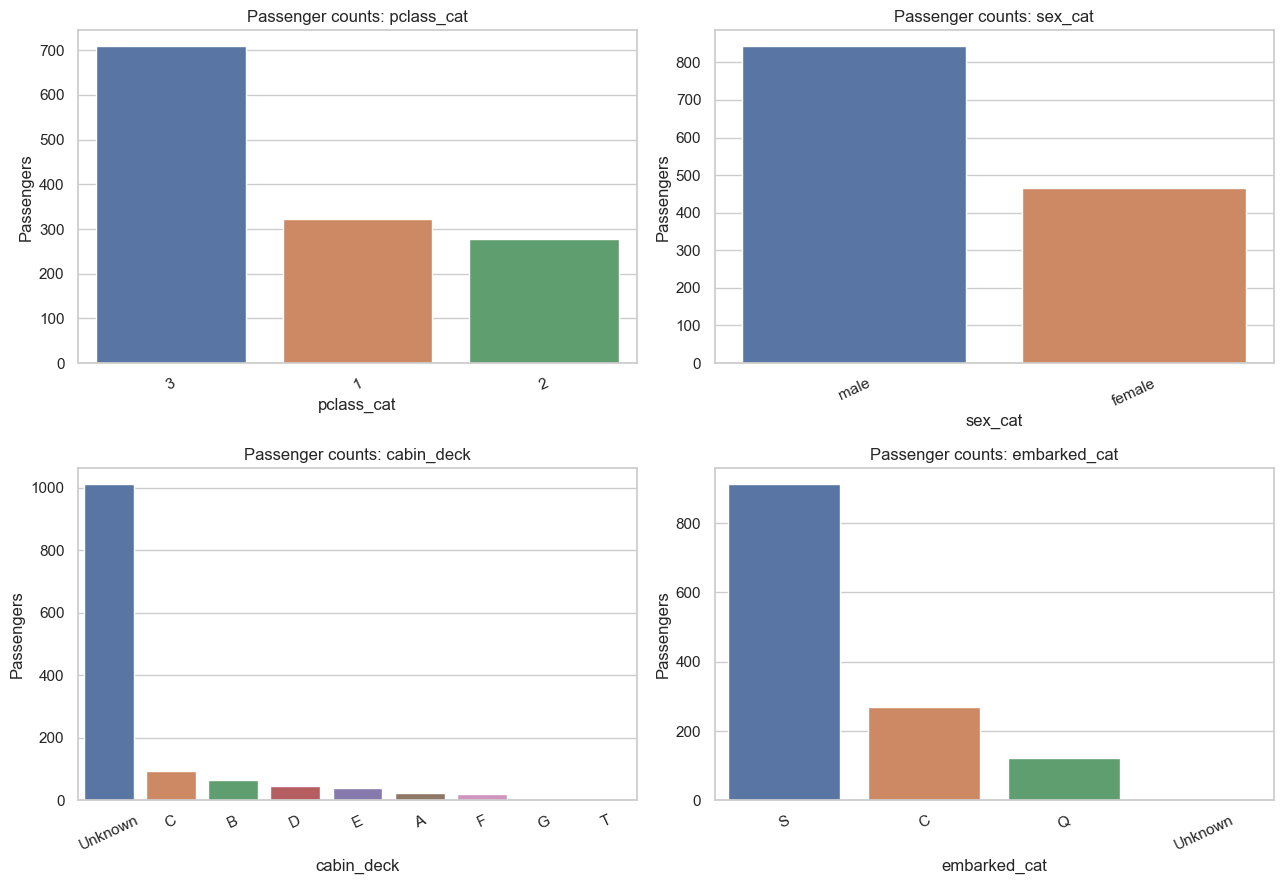

In [3]:
fig, axes = plt.subplots(2,2,figsize=(13,9))
for ax,c in zip(axes.flat,cat_cols):
    counts=work[c].value_counts().sort_values(ascending=False)
    sns.barplot(x=counts.index.astype(str),y=counts.values,hue=counts.index.astype(str),legend=False,ax=ax)
    ax.set(title=f"Passenger counts: {c}",xlabel=c,ylabel="Passengers"); ax.tick_params(axis="x",rotation=25)
plt.tight_layout(); plt.show()

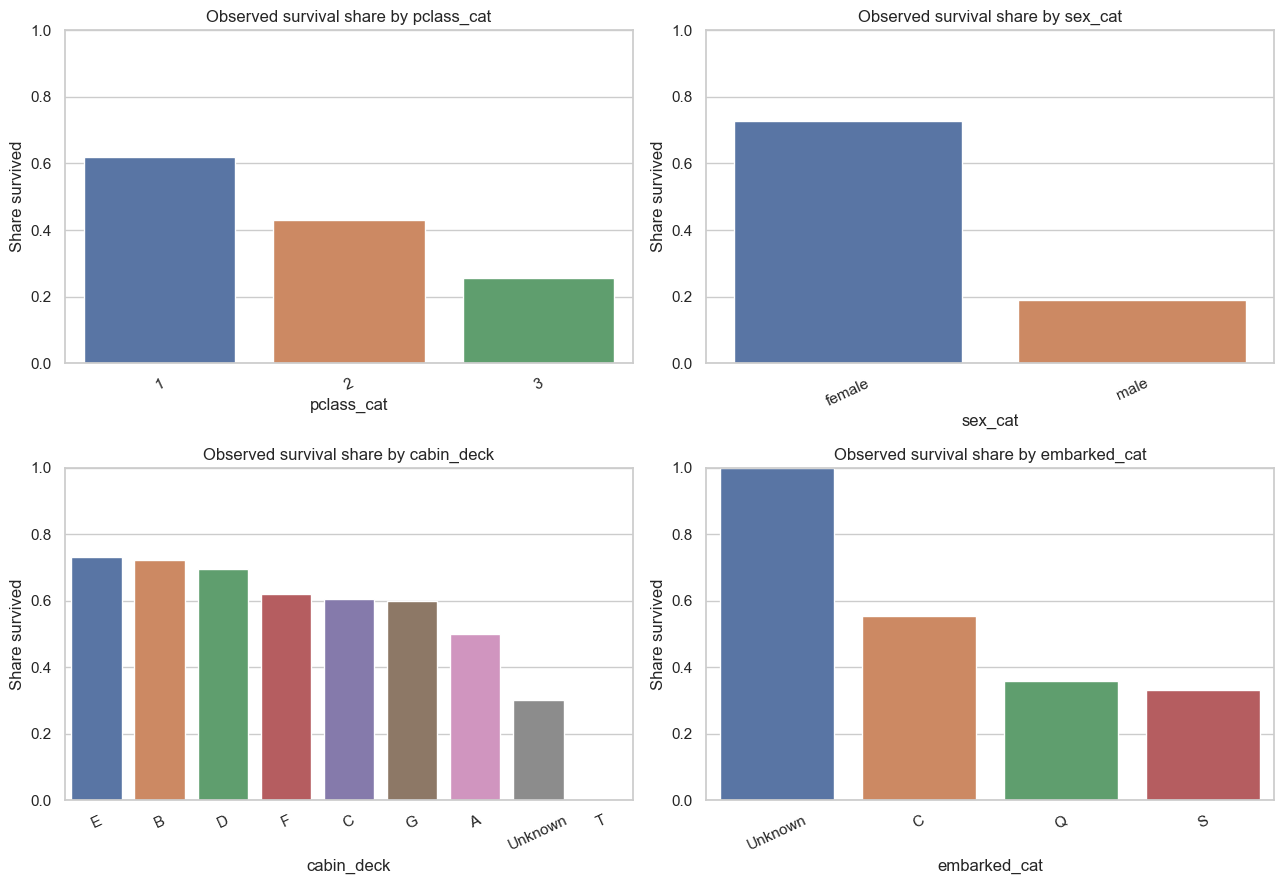

In [4]:
fig, axes=plt.subplots(2,2,figsize=(13,9))
for ax,c in zip(axes.flat,cat_cols):
    rates=work.groupby(c,dropna=False)["survived"].mean().sort_values(ascending=False)
    sns.barplot(x=rates.index.astype(str),y=rates.values,hue=rates.index.astype(str),legend=False,ax=ax)
    ax.set(title=f"Observed survival share by {c}",xlabel=c,ylabel="Share survived",ylim=(0,1)); ax.tick_params(axis="x",rotation=25)
plt.tight_layout(); plt.show()

## 4. Separate features and target; split before fitting

We reserve a stratified test set before fitting the encoder. This ensures the encoder learns categories from training data only. `boat` and `body` reveal information after the event and are not predictors. `survived` is kept separately as the outcome.

In [5]:
feature_cols=cat_cols+["age","sibsp","parch","fare"]
X=work[feature_cols].copy(); y=work["survived"].astype(int)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.30,random_state=0,stratify=y)
print("train",X_train.shape,"test",X_test.shape,"survival shares",round(y_train.mean(),3),round(y_test.mean(),3))

train (916, 8) test (393, 8) survival shares 0.382 0.382


## 5. Full one-hot encoding (all categories)

A feature with $k$ categories gets $k$ dummy columns. A row has a 1 in the matching column and 0 in the others. `handle_unknown="ignore"` means a category first encountered in test data will not cause an error; its indicators for that feature will all be zero.

In [6]:
full = OneHotEncoder(handle_unknown="ignore",sparse_output=False,dtype=np.int64)
train_full=pd.DataFrame(full.fit_transform(X_train[cat_cols]),columns=full.get_feature_names_out(cat_cols),index=X_train.index)
test_full=pd.DataFrame(full.transform(X_test[cat_cols]),columns=full.get_feature_names_out(cat_cols),index=X_test.index)
for c,cats in zip(cat_cols,full.categories_): print(c,list(cats))
print("Dummy columns:",train_full.shape[1]); display(train_full.head())

pclass_cat ['1', '2', '3']
sex_cat ['female', 'male']
cabin_deck ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'T', 'Unknown']
embarked_cat ['C', 'Q', 'S']
Dummy columns: 17


,pclass_cat_1,pclass_cat_2,pclass_cat_3,sex_cat_female,sex_cat_male,cabin_deck_A,cabin_deck_B,cabin_deck_C,cabin_deck_D,cabin_deck_E,cabin_deck_F,cabin_deck_G,cabin_deck_T,cabin_deck_Unknown,embarked_cat_C,embarked_cat_Q,embarked_cat_S
485,0,1,0,0,1,0,0,0,1,0,0,0,0,0,1,0,0
509,0,1,0,0,1,0,0,0,0,0,0,0,0,1,0,0,1
383,0,1,0,0,1,0,0,0,0,0,0,0,0,1,0,0,1
10,1,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0
654,0,0,1,0,1,0,0,0,0,0,0,0,0,1,1,0,0


### Check indicator behavior
Each training row should activate exactly one dummy for each encoded feature. This check verifies that categories are mutually exclusive and represented as intended.

In [7]:
names=full.get_feature_names_out(cat_cols)
for c in cat_cols:
    cols=[i for i,n in enumerate(names) if n.startswith(c+"_")]
    assert train_full.iloc[:,cols].sum(axis=1).eq(1).all()
print("Passed: one active training dummy per encoded variable.")

Passed: one active training dummy per encoded variable.


## 6. Top categories and grouping the rare tail

The attached material describes encoding only the most frequent categories. Here we learn the top two categories for each variable from training data and map all remaining categories to an explicit `Other` value. This makes the grouping visible and reduces feature width, but combines distinct rare categories and loses their individual information.

In [8]:
top_n=2
top={c:X_train[c].value_counts().head(top_n).index.tolist() for c in cat_cols}
print("Training top categories:",top)
def group_rare(frame):
    out=frame[cat_cols].copy()
    for c in cat_cols: out[c]=out[c].where(out[c].isin(top[c]),"Other")
    return out
train_grouped=group_rare(X_train); test_grouped=group_rare(X_test)
top_encoder=OneHotEncoder(handle_unknown="ignore",sparse_output=False,dtype=np.int64)
train_top=pd.DataFrame(top_encoder.fit_transform(train_grouped),columns=top_encoder.get_feature_names_out(cat_cols),index=X_train.index)
test_top=pd.DataFrame(top_encoder.transform(test_grouped),columns=top_encoder.get_feature_names_out(cat_cols),index=X_test.index)
print("Full width:",train_full.shape[1],"Top-2 + Other width:",train_top.shape[1]); display(train_grouped.head())

Training top categories: {'pclass_cat': ['3', '1'], 'sex_cat': ['male', 'female'], 'cabin_deck': ['Unknown', 'C'], 'embarked_cat': ['S', 'C']}
Full width: 17 Top-2 + Other width: 11


,pclass_cat,sex_cat,cabin_deck,embarked_cat
485,Other,male,Other,C
509,Other,male,Unknown,S
383,Other,male,Unknown,S
10,1,male,C,C
654,3,male,Unknown,C


## 7. Drop one reference category (k−1 encoding)

For linear models with an intercept, all $k$ indicators sum to one and can create perfect multicollinearity. `drop="first"` removes one category per feature, leaving $k-1$ columns. A row in the dropped category is represented by all zeros for that feature; it becomes the reference level. The category is not missing from the data. Some models work well with all $k$ indicators, so this choice depends on the model.

In [9]:
dropper=OneHotEncoder(handle_unknown="ignore",drop="first",sparse_output=False,dtype=np.int64)
train_drop=pd.DataFrame(dropper.fit_transform(X_train[cat_cols]),columns=dropper.get_feature_names_out(cat_cols),index=X_train.index)
test_drop=pd.DataFrame(dropper.transform(X_test[cat_cols]),columns=dropper.get_feature_names_out(cat_cols),index=X_test.index)
print("Full k columns:",train_full.shape[1],"Reference-dropped k-1:",train_drop.shape[1])
for c,cats in zip(cat_cols,dropper.categories_): print(c,"reference:",cats[0])

Full k columns: 17 Reference-dropped k-1: 13
pclass_cat reference: 1
sex_cat reference: female
cabin_deck reference: A
embarked_cat reference: C


/opt/anaconda3/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


## 8. Binary features and automatic category detection

For a binary feature, two dummy columns are redundant: one indicator determines the other. Scikit-learn's `drop="if_binary"` drops one category only for features with two observed training categories, while retaining full indicators for variables with more categories. We inspect `sex` separately to show the result.

In [10]:
binary_encoder=OneHotEncoder(handle_unknown="ignore",drop="if_binary",sparse_output=False,dtype=np.int64)
train_binary=pd.DataFrame(binary_encoder.fit_transform(X_train[cat_cols]),columns=binary_encoder.get_feature_names_out(cat_cols),index=X_train.index)
print("Sex categories:",list(binary_encoder.categories_[cat_cols.index("sex_cat")]))
print("Sex dummy columns:",[c for c in train_binary if c.startswith("sex_cat_")])
print("Widths — all k:",train_full.shape[1],"drop binary only:",train_binary.shape[1])
display(train_binary.filter(like="sex_cat_").head())

Sex categories: ['female', 'male']
Sex dummy columns: ['sex_cat_male']
Widths — all k: 17 drop binary only: 16


,sex_cat_male
485,1
509,1
383,1
10,1
654,1


## 9. Compare designs and visualize output width
Full encoding keeps every category distinction; reference dropping saves one column per variable; top-category grouping can substantially reduce columns by combining rare values.

,design,dummy_columns
0,Full categories (k),17
1,Reference category dropped (k−1),13
2,Top 2 + Other,11


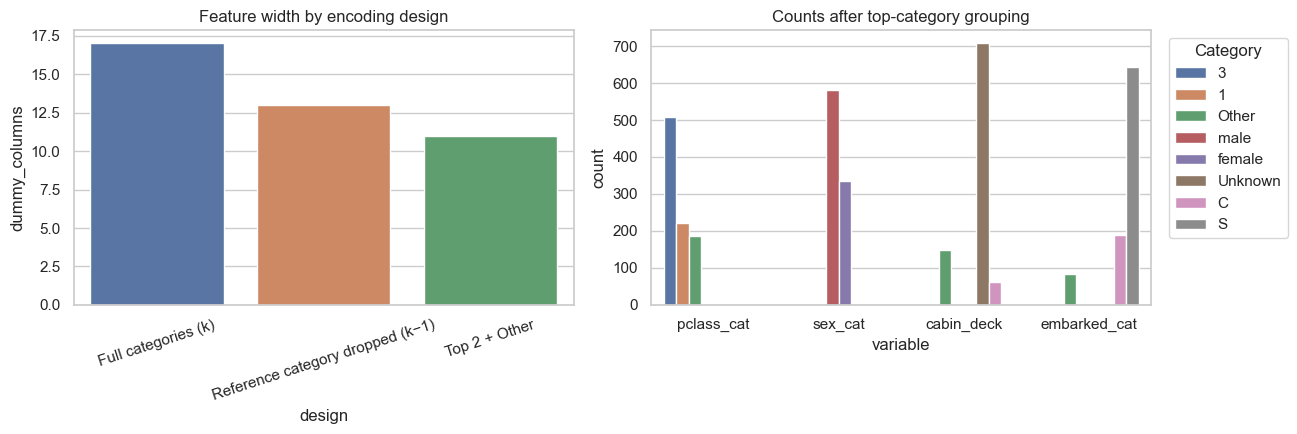

In [11]:
comparison=pd.DataFrame({"design":["Full categories (k)","Reference category dropped (k−1)","Top 2 + Other"],"dummy_columns":[train_full.shape[1],train_drop.shape[1],train_top.shape[1]]})
display(comparison)
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
sns.barplot(data=comparison,x="design",y="dummy_columns",hue="design",legend=False,ax=axes[0]); axes[0].set_title("Feature width by encoding design"); axes[0].tick_params(axis="x",rotation=18)
parts=[]
for c in cat_cols:
    t=train_grouped[c].value_counts().rename_axis("category").reset_index(name="count"); t["variable"]=c; parts.append(t)
counts=pd.concat(parts,ignore_index=True)
sns.barplot(data=counts,x="variable",y="count",hue="category",ax=axes[1]); axes[1].set_title("Counts after top-category grouping"); axes[1].legend(title="Category",bbox_to_anchor=(1.02,1),loc="upper left")
plt.tight_layout(); plt.show()

## 10. Visualize the binary indicator matrix
A heatmap of a small sample makes the 0/1 representation concrete. Each row is one passenger; highlighted cells are active categories.

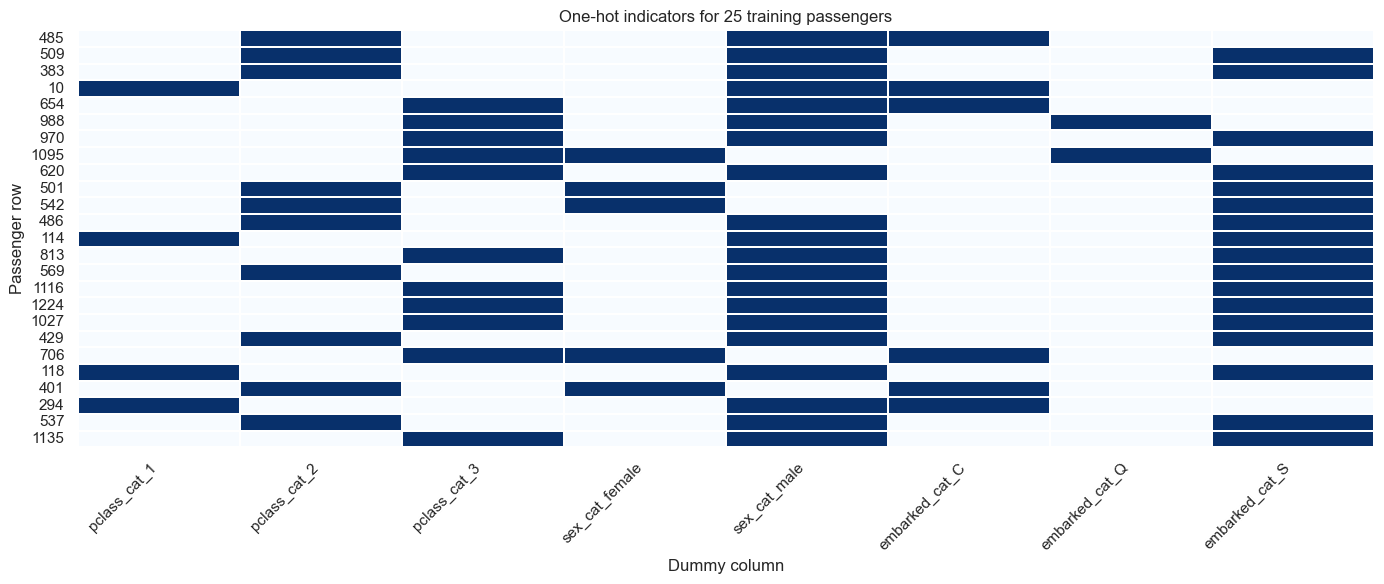

In [12]:
viz=[c for c in train_full if c.startswith(("pclass_cat_","sex_cat_","embarked_cat_"))]
plt.figure(figsize=(14,6)); sns.heatmap(train_full[viz].head(25),cmap="Blues",cbar=False,linewidths=.3,linecolor="white")
plt.title("One-hot indicators for 25 training passengers"); plt.xlabel("Dummy column"); plt.ylabel("Passenger row"); plt.xticks(rotation=45,ha="right"); plt.tight_layout(); plt.show()

## 11. Assemble model input and validate

We use the full-category design as the model input example. Numeric age and fare still contain missing values; this is an encoding demonstration, so no imputation is performed. A predictive workflow should impute inside a pipeline. The target remains outside the feature matrix.

In [13]:
numeric=["age","sibsp","parch","fare"]
X_train_encoded=pd.concat([X_train[numeric],train_full],axis=1).sort_index()
X_test_encoded=pd.concat([X_test[numeric],test_full],axis=1).sort_index().reindex(columns=X_train_encoded.columns)
assert X_train_encoded.columns.equals(X_test_encoded.columns)
assert set(np.unique(train_full.to_numpy())) <= {0,1}
assert set(y_train.unique()) <= {0,1}
print("Train features:",X_train_encoded.shape,"test features:",X_test_encoded.shape)
display(X_train_encoded.head())

Train features: (916, 21) test features: (393, 21)


,age,sibsp,parch,fare,pclass_cat_1,pclass_cat_2,pclass_cat_3,sex_cat_female,sex_cat_male,cabin_deck_A,...,cabin_deck_C,cabin_deck_D,cabin_deck_E,cabin_deck_F,cabin_deck_G,cabin_deck_T,cabin_deck_Unknown,embarked_cat_C,embarked_cat_Q,embarked_cat_S
0,29.0000,0,0,211.3375,1,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,1
1,0.9167,1,2,151.5500,1,0,0,0,1,0,...,1,0,0,0,0,0,0,0,0,1
2,2.0000,1,2,151.5500,1,0,0,1,0,0,...,1,0,0,0,0,0,0,0,0,1
3,30.0000,1,2,151.5500,1,0,0,0,1,0,...,1,0,0,0,0,0,0,0,0,1
4,25.0000,1,2,151.5500,1,0,0,1,0,0,...,1,0,0,0,0,0,0,0,0,1


## 12. Interpretation and limitations

- Full one-hot encoding creates one binary feature per category and avoids artificial numeric ordering.
- Top-category encoding reduces width but combines rare categories. Select the cutoff from training data and based on the modeling goal.
- Dropping a reference category can prevent perfect multicollinearity in linear models with an intercept; the omitted category becomes the comparison baseline.
- For binary variables, one dummy is sufficient.
- This analysis treats unknown/missing categorical values explicitly, extracts only the first cabin deck, and omits high-cardinality name/ticket fields.
- `boat` and `body` are excluded because they reveal post-event information; `survived` is kept solely as the target.
- Unknown categories ignored by the encoder produce all-zero indicators for that feature. Monitor this if categories can change.
- Age and fare need a separate missing-value strategy before most models. Fit preprocessing only on training data, ideally in a scikit-learn `Pipeline`/`ColumnTransformer`.

### Summary

The notebook demonstrates all main choices from the supplied material on Titanic data: all categories, top-category grouping, a dropped reference level, and a single dummy for binary variables. It visualizes category distributions and the resulting indicator matrix while keeping the target separate.